# Pipeline experiments

Fit once per case, keep the predictions, and inspect the same experiment in several ways. This restores the original multi-test workflow.

**Development notebook.** Expand the library cells to edit the implementation. Examples below use local data and CPU. [Build workflow](README.md#develop-the-package-here).

In [1]:
#| default_exp evaluation

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline
plt.style.use('default')
plt.rcParams.update({'figure.figsize': (12, 4), 'figure.dpi': 110,
    'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': False, 'legend.frameon': False, 'axes.titlelocation': 'left'})

## Build `evaluation`

### Imports and configuration

In [3]:
#| export evaluation
from __future__ import annotations

from dataclasses import dataclass, field
from typing import Any

from timegym.contracts import Forecast
from timegym.reporting import CaseResult, TestReport
from timegym.scenarios import Case

### EvaluatedCase — One generated case, its actual model output, and its diagnostic result.

In [4]:
#| export evaluation
@dataclass
class EvaluatedCase:
    """One generated case, its actual model output, and its diagnostic result.

    ``forecast`` is absent when model execution failed. Positional scenario
    and seed identities keep repeated scenario kinds and seeds distinct.
    """

    case: Case
    forecast: Forecast | None
    result: CaseResult
    scenario_index: int
    seed_index: int

### ForecastRun — Retain the evidence needed to inspect a run without fitting again.

In [5]:
#| export evaluation
@dataclass
class ForecastRun:
    """Retain the evidence needed to inspect a run without fitting again.

    Arrays remain in memory; ``report`` uses the existing JSON report schema
    and does not embed contexts, observations, or forecast arrays. Plotting
    requires the optional ``timegym[plots]`` dependencies, loaded on demand.
    """

    cases: list[EvaluatedCase]
    metadata: dict[str, Any] = field(default_factory=dict)

    @property
    def report(self) -> TestReport:
        """Return the usual structured report for these evaluated cases."""
        return TestReport(cases=[entry.result for entry in self.cases], metadata=self.metadata)

    def plot_forecasts(self, *, show_quantiles=False, figsize=None):
        """Plot scenario/target rows by seed columns, using retained outputs.

        Means are discrete blue crosses, observations are gray dots, and
        known conditional means are thin gray curves. Optional bands use
        explicit marginal quantiles; samples never imply a point forecast.
        """
        from timegym.plotting import plot_forecasts

        return plot_forecasts(self, show_quantiles=show_quantiles, figsize=figsize)

    def plot_errors(self, metric="mean_reference_mse", *, bins=None, missing="raise", figsize=None):
        """Plot per-scenario score distributions without rerunning a model.

        Missing/nonfinite scores raise by default. Set ``missing='annotate'``
        to show their counts and diagnostic reasons explicitly in each panel.
        Each score is one whole-case metric from the existing report.
        """
        from timegym.plotting import plot_errors

        return plot_errors(self, metric=metric, bins=bins, missing=missing, figsize=figsize)

## Build `pipeline`

### Imports and configuration

In [6]:
# Keep the live source types before the next module's package imports.
_notebook_run_types = (EvaluatedCase, ForecastRun)

In [7]:
#| export pipeline
from __future__ import annotations
from timegym._internal import positive_int, nonnegative_int

import inspect
import numpy as np
import pandas as pd
from timegym.contracts import Forecast, ForecastTask
from timegym.models import NaiveForecaster, SklearnForecaster, fresh_model, is_sklearn_regressor
from timegym.scenarios import Scenario, MANIFEST_SCHEMA_VERSION
from timegym.data.synthetic import default_scenarios
from timegym.diagnostics import evaluate_forecast, exception_evidence
from timegym.reporting import CaseResult, DiagnosticResult, TestReport
from timegym.evaluation import EvaluatedCase, ForecastRun
from timegym.provenance import pipeline_config, pipeline_from_config, diagnostic_settings, runtime_provenance


### Pipeline — Evaluate fresh model instances on independent, seeded scenarios.

In [8]:
#| export pipeline
class Pipeline:
    """Evaluate fresh model instances on independent, seeded scenarios.

    Native models implement fit(context: DataFrame) and predict(future_index),
    returning a Forecast. Supply a native class, a model_factory producing a
    fresh unfitted instance, or an instance implementing clone_unfitted().
    sklearn regressors/transformers can be added with add().
    Only recursive sklearn reduction is supported in this focused release.
    """

    def __init__(self, model=None, window_length=12, reduction="recursive", *, model_factory=None):
        if reduction != "recursive":
            raise ValueError("This release supports reduction='recursive' only")
        self.model = model
        if model is not None and model_factory is not None:
            raise ValueError("Specify model or model_factory, not both")
        if model_factory is not None and not callable(model_factory):
            raise TypeError("model_factory must be a callable producing a fresh unfitted model")
        self.model_factory = model_factory
        window_length = positive_int(window_length, 'window_length')
        self.window_length = int(window_length)
        self.reduction = reduction
        self.steps = []

    def add(self, estimator, **parameters):
        """Add an sklearn transformer or final regressor; returns self."""
        if self.model is not None or self.model_factory is not None:
            raise ValueError("Use a native model or sklearn steps, not both")
        if inspect.isclass(estimator):
            estimator = estimator(**parameters)
        elif parameters:
            estimator = fresh_model(estimator).set_params(**parameters)
        self.steps.append(estimator)
        return self

    def _model(self):
        if self.steps:
            return SklearnForecaster(self.steps, self.window_length)
        if self.model is None and self.model_factory is None:
            return NaiveForecaster()
        newly_constructed = self.model_factory is not None or inspect.isclass(self.model)
        candidate = self.model_factory() if self.model_factory is not None else (self.model() if inspect.isclass(self.model) else self.model)
        if callable(getattr(candidate, "clone_unfitted", None)):
            return candidate if newly_constructed else fresh_model(candidate)
        if is_sklearn_regressor(candidate):
            return SklearnForecaster([candidate], self.window_length)
        return candidate if newly_constructed else fresh_model(candidate)

    def _model_name(self) -> str:
        if self.steps:
            return "SklearnForecaster"
        if self.model_factory is not None:
            return getattr(self.model_factory, "__qualname__", "model_factory")
        if inspect.isclass(self.model):
            return self.model.__name__
        if self.model is not None:
            return type(self.model).__name__
        return "NaiveForecaster"

    def to_config(self):
        """Return JSON-safe configuration and whether safe automatic replay is supported."""
        return pipeline_config(self)

    @classmethod
    def from_config(cls, config):
        """Reconstruct only an allowlisted built-in model, without dynamic imports."""
        return cls(**pipeline_from_config(config))

    def predict(self, context, future_index):
        """Fit on context and predict the supplied index, without future targets."""
        if isinstance(context, pd.Series):
            context = context.to_frame(name=context.name if context.name is not None else "y")
        # Share the public task contract, including unique target names.
        ForecastTask(context=context, future_index=future_index)
        model = self._model()
        model.fit(context.copy(deep=True))
        forecast = model.predict(future_index.copy())
        if not isinstance(forecast, Forecast):
            raise TypeError("Native model.predict must return a timegym.Forecast")
        return forecast

    def run(self, scenarios=None, seeds=(0, 1, 2), *, check_dependence=False,
            n_calibration=99, alpha=0.05, dependence_seed_offset=100_000):
        """Evaluate once per case and retain the data, forecast, and diagnostics.

        ``run.report`` provides the unchanged serializable report interface;
        ``run.plot_forecasts()`` and ``run.plot_errors()`` inspect these exact
        outputs without additional fitting or predictive sampling.
        """
        if self.steps:
            SklearnForecaster(self.steps, self.window_length)
        settings = diagnostic_settings(check_dependence=check_dependence, n_calibration=n_calibration,
                                       alpha=alpha, dependence_seed_offset=dependence_seed_offset)
        if scenarios is None:
            scenarios = default_scenarios()
        scenarios, seeds = list(scenarios), list(seeds)
        if not scenarios or not seeds:
            raise ValueError("Provide at least one scenario and one seed")
        results = []
        for scenario_index, scenario in enumerate(scenarios):
            for seed_index, seed in enumerate(seeds):
                case = scenario.generate(seed=seed)
                forecast = None
                try:
                    forecast = self.predict(case.task.context, case.task.future_index)
                    result = evaluate_forecast(case, forecast, check_dependence=check_dependence,
                                               dependence_seed=int(seed) + dependence_seed_offset,
                                               n_calibration=n_calibration, alpha=alpha)
                except Exception as exc:
                    result = CaseResult(scenario=scenario.kind, seed=int(seed), diagnostics=[
                        DiagnosticResult(name="model_execution", status="ERROR", category="execution",
                                         message=f"{type(exc).__name__}: {exc}",
                                         evidence=exception_evidence(exc))],
                        metrics={}, manifest=case.manifest)
                results.append(EvaluatedCase(case=case, forecast=forecast, result=result,
                                             scenario_index=scenario_index, seed_index=seed_index))
        return ForecastRun(cases=results, metadata={**runtime_provenance(), "numpy": np.__version__,
                          "pandas": pd.__version__, "model": self._model_name(),
                          "window_length": self.window_length, "reduction": self.reduction,
                          "pipeline_config": self.to_config(), "diagnostic_settings": settings})

    def test(self, scenarios=None, seeds=(0, 1, 2), *, check_dependence=False,
             n_calibration=99, alpha=0.05, dependence_seed_offset=100_000):
        """Return a machine-readable TestReport; statistical uncertainty is explicit."""
        return self.run(scenarios, seeds=seeds, check_dependence=check_dependence,
                        n_calibration=n_calibration, alpha=alpha,
                        dependence_seed_offset=dependence_seed_offset).report

    def plot_tests(self, scenarios=None, seeds=(0, 1, 2), *, show_quantiles=False,
                   figsize=None, **diagnostic_settings):
        """Fit a display suite and return its forecast matrix Figure.

        Display defaults use 240 context observations and 80 forecast steps;
        ``test`` and ``run`` retain their existing scenario defaults. To make
        several figures from the same fits, use ``run`` and its plot methods.
        """
        if scenarios is None:
            scenarios = default_scenarios(context_length=240, horizon=80)
        return self.run(scenarios, seeds=seeds, **diagnostic_settings).plot_forecasts(
            show_quantiles=show_quantiles, figsize=figsize)

    def plot_errors(self, scenarios=None, seeds=tuple(range(20)), *, metric="mean_reference_mse",
                   bins=None, missing="raise", figsize=None, **diagnostic_settings):
        """Fit once per requested case and plot the retained score distribution.

        This convenience call evaluates a new run. Use an existing run's
        ``plot_errors`` method to inspect previously evaluated forecasts.
        """
        return self.run(scenarios, seeds=seeds, **diagnostic_settings).plot_errors(
            metric=metric, bins=bins, missing=missing, figsize=figsize)

    def plot_error(self, *args, **kwargs):
        """Compatibility alias for plot_errors, retained for the 0.2 release."""
        return self.plot_errors(*args, **kwargs)

In [18]:
#| export pipeline
def _without_tracebacks(value):
    if isinstance(value, dict):
        return {key: _without_tracebacks(item) for key, item in value.items() if key != "traceback"}
    if isinstance(value, list):
        return [_without_tracebacks(item) for item in value]
    return value


def _tracebacks(value, path=()):
    found = {}
    if isinstance(value, dict):
        for key, item in value.items():
            if key == "traceback":
                found[path + (key,)] = item
            else:
                found.update(_tracebacks(item, path + (key,)))
    elif isinstance(value, list):
        for index, item in enumerate(value):
            found.update(_tracebacks(item, path + (index,)))
    return found


def replay_case(report: TestReport, case_index=0):
    """Replay one report case and compare regenerated metrics and diagnostics.

    The return value is a new TestReport. ``metadata['replay']`` records exact
    result equality excluding tracebacks, plus traceback and environment agreement.
    Replaying in a different environment is allowed and reported.
    """
    if not isinstance(report, TestReport):
        raise TypeError("replay_case requires a TestReport; load saved data with TestReport.from_dict")
    payload = report.to_dict()
    case_index = nonnegative_int(case_index, "case_index")
    if case_index >= len(report.cases):
        raise ValueError("case_index is outside the saved report")
    original = payload["cases"][case_index]
    saved_metadata = payload["metadata"]
    pipeline = Pipeline.from_config(saved_metadata.get("pipeline_config"))
    settings = saved_metadata.get("diagnostic_settings")
    setting_keys = {"check_dependence", "n_calibration", "alpha", "dependence_seed_offset"}
    if not isinstance(settings, dict) or set(settings) != setting_keys:
        raise ValueError("Report diagnostic settings are absent or unsupported")
    settings = diagnostic_settings(**settings)
    manifest = original["manifest"]
    if type(manifest.get("schema_version")) is not int or manifest["schema_version"] != MANIFEST_SCHEMA_VERSION:
        raise ValueError("Unsupported scenario manifest schema")
    constructor_keys = ("kind", "context_length", "horizon", "parameters", "n_targets", "seed")
    if any(key not in manifest for key in constructor_keys):
        raise ValueError("Scenario manifest lacks required reconstruction fields")
    if original.get("seed") != manifest["seed"] or original.get("scenario") != manifest["kind"]:
        raise ValueError("Case identity and scenario manifest disagree")
    scenario = Scenario(**{key: manifest[key] for key in constructor_keys})
    regenerated = pipeline.test([scenario], seeds=[manifest["seed"]], **settings)
    actual = regenerated.cases[0].to_dict()
    regenerated.metadata["replay"] = {
        "case_index": case_index,
        "metrics_match": actual["metrics"] == original.get("metrics"),
        "diagnostics_match": _without_tracebacks(actual["diagnostics"]) == _without_tracebacks(original["diagnostics"]),
        "traceback_match": _tracebacks(actual["diagnostics"]) == _tracebacks(original["diagnostics"]),
        "manifest_match": actual["manifest"] == manifest,
        "source_matches": regenerated.metadata["source"] == saved_metadata.get("source"),
        "dependencies_match": regenerated.metadata["dependencies"] == saved_metadata.get("dependencies"),
        "python_matches": regenerated.metadata["python"] == saved_metadata.get("python"),
    }
    comparison = regenerated.metadata["replay"]
    comparison["reproduced"] = all(comparison[key] for key in ("metrics_match", "diagnostics_match", "manifest_match"))
    comparison["same_environment"] = all(comparison[key] for key in ("source_matches", "dependencies_match", "python_matches"))
    return regenerated

## One run, several stochastic cases

In [9]:
# Pipeline.run resolves these globals when called, so keep its live local
# result types rather than the previously exported copies imported above.
EvaluatedCase, ForecastRun = _notebook_run_types
assert EvaluatedCase.__module__ == ForecastRun.__module__ == __name__
assert Pipeline.__module__ == __name__

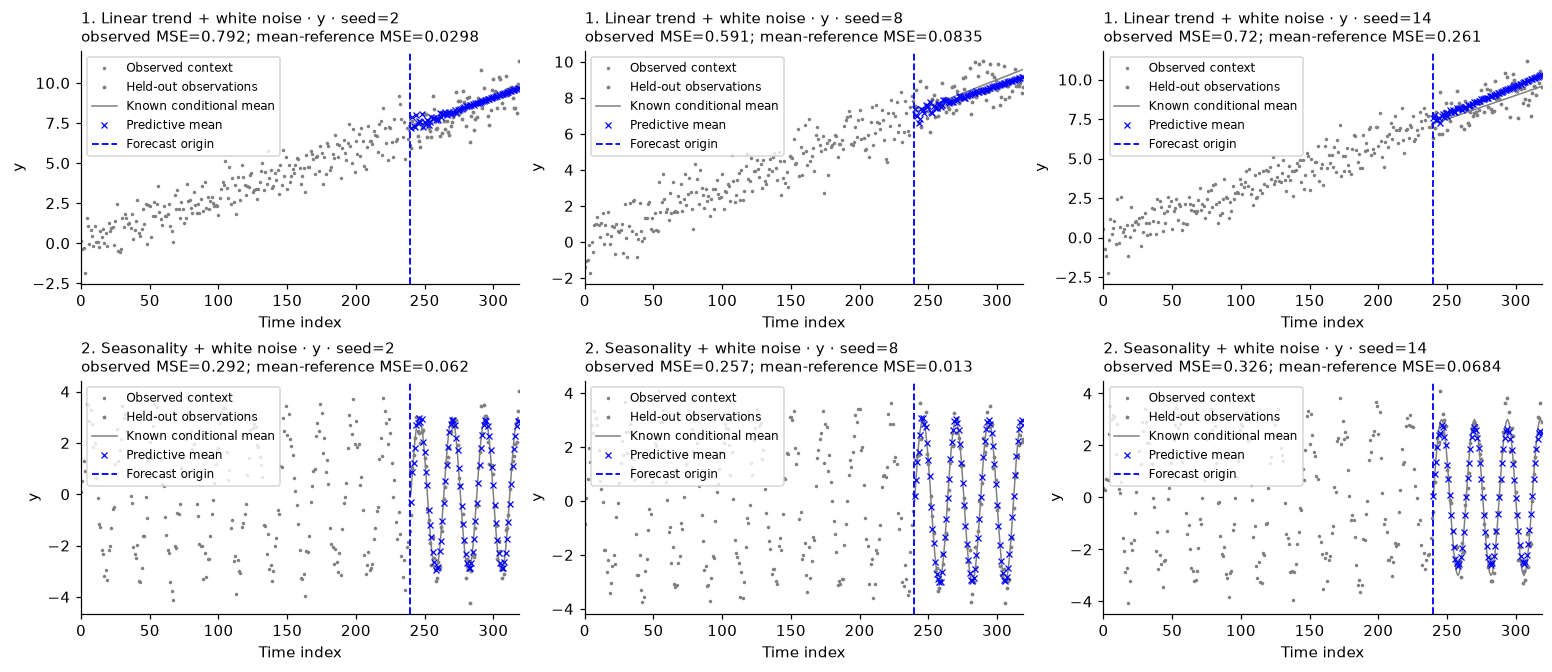

{'cases': 6,
 'diagnostics': 24,
 'status_counts': {'PASS': 6,
  'FAIL': 0,
  'INCONCLUSIVE': 6,
  'UNSUPPORTED': 12,
  'ERROR': 0},
 'failed_cases': 0}

In [10]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from timegym import Scenario
pipeline = Pipeline(window_length=24).add(StandardScaler()).add(Ridge(alpha=1.))
specifications = [Scenario('trend', 240, 80, {'slope': .03, 'sigma': .8}),
                   Scenario('seasonal', 240, 80, {'amplitude': 3., 'period': 24., 'sigma': .5})]
run = pipeline.run(specifications, seeds=[2, 8, 14])
assert type(run) is ForecastRun
assert all(type(entry) is EvaluatedCase for entry in run.cases)
run.plot_forecasts(figsize=(14, 6));
plt.show()
assert len(run.cases) == len(specifications) * 3
display(run.report.summary)

Gray dots are observations; blue crosses are predicted means. Plotting reads retained predictions and never refits the model. A failed case stays visible instead of disappearing from the comparison.

## A distribution requires several cases

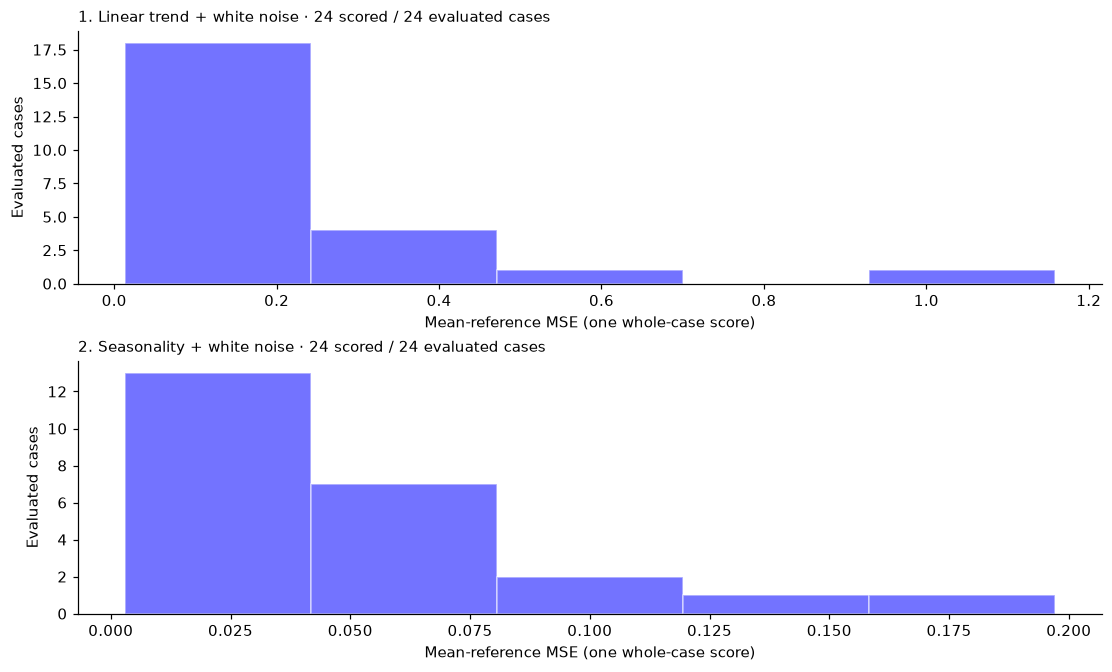

In [11]:
replications = pipeline.run(specifications, seeds=range(24))
replications.plot_errors(metric='mean_reference_mse');
plt.show()

Each value is one generated case. The plot does not treat dependent forecast horizons as independent replications. Change one model setting, preserve the same seeds, and compare again.

## Edit, run, export

After editing a source cell, **restart this kernel and Run All**. This refreshes the local definitions, the development bindings between modules in this chapter, and the nearby examples. Ordinary Run All does not export files.

Changes to code owned by another chapter require saving that source notebook, running `python tools/export_notebooks.py`, and restarting this kernel before importing the updated package. Runtime provenance describes the exported package, not unexported edits.

Try one implementation or parameter change, rerun this chapter, and inspect the figure or assertion. Save the notebook before exporting.